---
title: "October-December 2023, one to six months ahead"
subtitle: "Seasonal rainfall forecasts for Indonesia from six CFSv2 start dates, calibrated with CCA and PCR"
description: "Build October-December CHIRPS v3.0 totals from dekads, download CFSv2 for starts one to six months before October 2023, fit CCA and PCR at each lead with PyCPT, compare skill by lead with the monthly case, and check the 2023 forecasts."
execute:
  enabled: false
---

The [monthly lead-time case](monthly-leads-2023.ipynb) forecast November 2023 from
six start dates. This notebook asks the same question for the **season** used
throughout the tutorial, October-December (OND) 2023: from a start one month
before October, two months before, and so on back to six months before. Everything
else is held fixed, so the only thing that changes from row to row is how far
ahead the forecast was made.

The one-month-ahead start, 1 September, is the running example of Learn PyCPT. The
design (target season, six starts, model, settings, training years, scores) is the
monthly case's, fixed before any skill was computed.

::: {.callout-note title="What you need to run this page"}
The full PyCPT environment with its CPT engine, internet access the first time
(twelve CFSv2 files from the IRI Data Library, no key needed), and the CHIRPS v3.0
dekadal archive described in step 2. The twelve fits take several minutes; times
are printed below.
:::

## 1. Six start dates for one target season

The **lead** here is the number of whole months between the start date and the
first day of the season: a 1 September start is one month ahead of OND, a 1 April
start is six months ahead. PyCPT gives a lead for each month of the season,
measured from the start to the middle of that month, so a season spans three
PyCPT leads: 1.5 to 3.5 for the September start, 6.5 to 8.5 for the April start.
The cell asks PyCPT's catalog helper for them.

In [1]:
from pathlib import Path
import datetime as dt
import json
import re
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely
import xarray as xr
import cartopy.io.shapereader as shapereader
import cptdl as dl
import pycpt

repo = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pycpt_tutorial").is_dir()), None)
if repo is None:
    raise FileNotFoundError("Run this notebook inside the tutorial repository or kit.")
sys.path.insert(0, str(repo))
from pycpt_tutorial.country_grid import aggregate_country_rainfall, training_complete_mask
from pycpt_tutorial.export import save_netcdf
from pycpt_tutorial import checks, figures
figures.use_style()

predictor_names = ["CFSv2.PRCP"]
predictand_name = "CHIRPS3.PRCP"
target = "Oct-Dec"
leads = [1, 2, 3, 4, 5, 6]                                  # months between start and 1 October
starts = {lead: dt.datetime(2023, 10 - lead, 1) for lead in leads}
predictor_extent = {"west": 85, "east": 155, "south": -20, "north": 20}
predictand_extent = {"west": 94, "east": 142, "south": -12, "north": 7}
training_years = list(range(1991, 2021))
cpt_args = {
    "transform_predictand": None,
    "tailoring": None,
    "cca_modes": (2, 2),
    "x_eof_modes": (3, 3),
    "y_eof_modes": (3, 3),
    "validation": "crossvalidation",
    "drymask_threshold": None,
    "skillmask_threshold": None,
    "crossvalidation_window": 5,
    "synchronous_predictors": True,
}
force_download = False
case_root = Path.home() / "PyCPT" / "indonesia-ond-2023-leads"

rows = []
for lead, start in starts.items():
    low, high = dl.leads_from_target(start, target)
    rows.append({"lead (months)": lead, "start": start.strftime("%d %b %Y"),
                 "PyCPT lead": f"{low} to {high}"})
pd.DataFrame(rows).set_index("lead (months)")

,start,PyCPT lead
lead (months),,
1,01 Sep 2023,1.5 to 3.5
2,01 Aug 2023,2.5 to 4.5
3,01 Jul 2023,3.5 to 5.5
4,01 Jun 2023,4.5 to 6.5
5,01 May 2023,5.5 to 7.5
6,01 Apr 2023,6.5 to 8.5


## 2. Seasonal observations from dekads

The predictand is OND rainfall from CHIRPS v3.0, built the same way as in the
monthly case: from the local **dekadal** archive (three accumulation periods per
month: days 1-10, 11-20 and 21 to the end), with exact zeros kept. An OND total
is the sum of nine dekads. The cell checks from the stored time bounds that they
are contiguous and cover exactly 1 October to 1 January before summing anything.

In [2]:
chirps3_file = Path("/mnt/e/temp/chirps/dekad/wld_cli_chirps3_dekad_1981_2025.nc")
source = xr.open_dataset(chirps3_file)
print("Variable attributes:", {k: source.precip.attrs[k] for k in ("units", "cell_methods", "comment")})

years = training_years + [2023]
stamps = pd.DatetimeIndex(source.time.values)
picks = {}
for year in years:
    index = np.flatnonzero((stamps.year == year) & stamps.month.isin([10, 11, 12]))
    bounds = pd.DatetimeIndex(source.time_bnds.isel(time=index).values.ravel())
    assert len(index) == 9
    assert bounds[0] == pd.Timestamp(year, 10, 1) and bounds[-1] == pd.Timestamp(year + 1, 1, 1)
    assert all(bounds[2 * k + 1] == bounds[2 * k + 2] for k in range(8))   # each dekad ends where the next begins
    picks[year] = index
print(f"October-December dekads found and contiguous for all {len(years)} years ({years[0]}-{years[-2]} and {years[-1]})")

box = predictand_extent
start = time.monotonic()
region = source.precip.sel(lon=slice(box["west"], box["east"]), lat=slice(box["south"], box["north"]))
season = xr.concat([region.isel(time=picks[y]).sum("time", skipna=False) for y in years],
                     dim=pd.Index(years, name="year")).load()
print(f"Read and summed {dict(season.sizes)} in {time.monotonic() - start:.0f} s")
print("Negative values:", int((season < 0).sum()))

Variable attributes: {'units': 'mm', 'cell_methods': 'time: sum', 'comment': 'Exact zeros are preserved, for a zero-inflated distribution fit. NaN marks no data.'}


October-December dekads found and contiguous for all 31 years (1991-2020 and 2023)


Read and summed {'year': 31, 'lat': 380, 'lon': 960} in 8 s
Negative values: 0


A consistency check against a separately stored product: the archive also has
3-month totals (the file chapter 3 used). The nine-dekad sums should equal the
stored October-December totals. The cell compares them for the first and last
year used here.

In [3]:
rolling = xr.open_dataset("/mnt/e/temp/chirps/rolling_dekad/wld_cli_chirps3_month3_bydekad_1981_2025.nc")
rolling_time = pd.DatetimeIndex(rolling.time.values)
for year in [1991, 2023]:
    from_dekads = season.sel(year=year, drop=True)
    k = int(np.flatnonzero((rolling_time.year == year) & (rolling_time.month == 12) & (rolling_time.day == 21))[0])
    b = pd.DatetimeIndex(rolling.time_bnds.isel(time=k).values)
    stored = rolling.precip.sel(lon=slice(box["west"], box["east"]), lat=slice(box["south"], box["north"])).isel(time=k).load()
    gap = abs(from_dekads - stored)
    print(f"OND {year} ({b[0]:%d %b %Y} to {b[1]:%d %b %Y}): largest difference {float(gap.max()):.4f} mm, "
          f"same missing pixels: {bool((from_dekads.isnull() == stored.isnull()).all())}")

OND 1991 (01 Oct 1991 to 01 Jan 1992): largest difference 0.0002 mm, same missing pixels: True


OND 2023 (01 Oct 2023 to 01 Jan 2024): largest difference 0.0002 mm, same missing pixels: True


The 0.25° grid and the Indonesia land rule are the ones from chapter 3: a cell is
the cosine-latitude weighted mean of the Indonesian 0.05° pixels inside it, kept
only when at least 99% of its country-land weight has data, and a cell enters
the fit only if it has data in all 30 training years.

In [4]:
records = shapereader.Reader(shapereader.natural_earth("10m", "cultural", "admin_0_countries")).records()
indonesia = next(r.geometry for r in records if r.attributes["ADM0_A3"] == "IDN")
shapely.prepare(indonesia)
lon2d, lat2d = np.meshgrid(season.lon, season.lat)
country = xr.DataArray(shapely.contains_xy(indonesia, lon2d, lat2d), dims=("lat", "lon"),
                       coords={"lat": season.lat, "lon": season.lon})
print(f"Native pixels inside Indonesia: {int(country.sum()):,}")
print("Indonesian pixels with exactly 0 mm in an OND season:", int(((season == 0) & country).sum()))

centres_y = box["south"] + 0.125 + np.arange(76) * 0.25
centres_x = box["west"] + 0.125 + np.arange(192) * 0.25
months = [aggregate_country_rainfall(season.sel(year=y, drop=True), country, 5, minimum_coverage=0.99)
          .precipitation.rename({"lat": "Y", "lon": "X"}).assign_coords(Y=centres_y, X=centres_x)
          .sortby("Y", ascending=False) for y in years]
observed_2023 = months[-1]

Native pixels inside Indonesia: 61,192
Indonesian pixels with exactly 0 mm in an OND season: 1


PyCPT needs the observations on the same time axis as the model hindcasts: one
`T` per year with the target's first and last day in `Ti` and `Tf`. The first
start's hindcasts are downloaded here to borrow that axis; step 3 checks the other
five starts share it.

In [5]:
first = dict(fdate=starts[1], target=target, target_first_year=training_years[0],
             target_final_year=training_years[-1], predictor_extent=predictor_extent,
             predictand_extent=predictand_extent)
first_dir = pycpt.setup(case_root / "lead-1", predictor_extent)
from pycpt import notebook as pycpt_notebook
hindcasts = pycpt_notebook.download_hindcasts(predictor_names, first_dir, force_download, first)[0]
model_time = pd.Index(hindcasts["T"].values, name="T")
assert (model_time.year == np.array(training_years)).all()

Y = (xr.concat(months[:-1], dim=model_time)
     .assign_coords(Ti=("T", hindcasts["Ti"].values), Tf=("T", hindcasts["Tf"].values)))
assert "S" not in Y.coords
complete = training_complete_mask(Y, training_years)
Y = Y.where(complete).transpose("T", "Y", "X").rename("precipitation")
Y.attrs = {"units": "mm", "missing": -999.0,
           "long_name": "CHIRPS v3.0 OND rainfall total, Indonesia land, 0.25 degree"}
cells = complete
observed_2023 = observed_2023.where(cells)

local_predictand_file = case_root / "local-CHIRPS3-OND-1991-2020-dekads.nc"
save_netcdf(Y.to_dataset(), local_predictand_file, overwrite=True,
            metadata={"source_file": chirps3_file.name,
                      "aggregation": "sum of nine dekads; cos-latitude weighted mean of Indonesian 0.05 degree pixels per 0.25 degree cell; at least 99% country-land coverage",
                      "boundary": "Natural Earth 1:10m admin_0_countries, ADM0_A3=IDN",
                      "training_years": "1991-2020"})
print(f"Cells with data in all 30 seasons: {int(cells.sum())}")
print("Target of the first value:", str(Y["Ti"].values[0])[:10], "to", str(Y["Tf"].values[0])[:10])
print(f"OND totals: median {float(Y.median()):.0f} mm, range {float(Y.min()):.1f} to {float(Y.max()):.1f} mm")

Input data will be saved in ~/PyCPT/indonesia-ond-2023-leads/lead-1/85W-155E_to_-20S-20N/data
Figures will be saved in ~/PyCPT/indonesia-ond-2023-leads/lead-1/85W-155E_to_-20S-20N/figures
Output will be saved in ~/PyCPT/indonesia-ond-2023-leads/lead-1/85W-155E_to_-20S-20N/output
URL: https://iridl.ldeo.columbia.edu/SOURCES/.Models/.NMME/.NCEP-CFSv2/.HINDCAST/.PENTAD_SAMPLES_FULL/.prec/S/%280000%201%20Sep%201991-2020%29/VALUES/L/1.5/3.5/RANGEEDGES/%5BL%5D//keepgrids/average/Y/-20/20/RANGEEDGES/X/85/155/RANGEEDGES/%5BM%5D/average/92/mul/-999/setmissing_value/%5BX/Y%5D%5BL/S/add%5D/cptv10.tsv


DOWNLOADING: [*************************] (1274 KB) 0:00:16.067095



Cells with data in all 30 seasons: 3240
Target of the first value: 1991-10-01 to 1991-12-31
OND totals: median 769 mm, range 5.8 to 3470.0 mm


The tutorial already has OND observations on this grid, built in chapter 3 from
the 3-month archive and saved with the Fit & diagnose case. Built from dekads
instead, they should agree to within rounding.

In [6]:
earlier = xr.open_dataset(repo / "docs/data/fitting-2023/OND-Y.nc").precipitation.load()
print("Same missing-value pattern:", bool((earlier.notnull() == Y.notnull()).all()))
print("Same target dates:", bool((earlier["T"].values == Y["T"].values).all()))
print(f"Largest difference: {float(abs(earlier - Y).max()):.4f} mm")

Same missing-value pattern: True
Same target dates: True
Largest difference: 0.0003 mm


## 3. One case folder per start

Each start is its own forecast question, so each gets its own case folder
([chapter 7](../learn/07-adapt-your-region.ipynb) explains why folders should not
be shared between questions). All six use the same local observation file.

In [7]:
inputs = {}
for lead, start in starts.items():
    args = dict(first, fdate=start)
    domain_dir = pycpt.setup(case_root / f"lead-{lead}", predictor_extent)
    checks.remember_question(args, domain_dir)
    Yl, hindcast_data, forecast_data = pycpt.download_data(
        predictand_name, local_predictand_file, predictor_names, args, domain_dir, force_download)
    inputs[lead] = dict(args=args, domain_dir=domain_dir, Y=Yl, X=hindcast_data, F=forecast_data)

Input data will be saved in ~/PyCPT/indonesia-ond-2023-leads/lead-1/85W-155E_to_-20S-20N/data
Figures will be saved in ~/PyCPT/indonesia-ond-2023-leads/lead-1/85W-155E_to_-20S-20N/figures
Output will be saved in ~/PyCPT/indonesia-ond-2023-leads/lead-1/85W-155E_to_-20S-20N/output
URL: https://iridl.ldeo.columbia.edu/SOURCES/.Models/.NMME/.NCEP-CFSv2/.HINDCAST/.PENTAD_SAMPLES_FULL/.prec/S/%280000%201%20Sep%202023%29/VALUES/L/1.5/3.5/RANGEEDGES/%5BL%5D//keepgrids/average/Y/-20/20/RANGEEDGES/X/85/155/RANGEEDGES/%5BM%5D/average/92/mul/-999/setmissing_value/%5BX/Y%5D%5BL/S/add%5D/cptv10.tsv


DOWNLOADING: [*************************] (45 KB) 0:00:00.761360

Using local observed predictand dataset
Reusing already-downloaded CFSv2.PRCP

Input data will be saved in ~/PyCPT/indonesia-ond-2023-leads/lead-2/85W-155E_to_-20S-20N/data
Figures will be saved in ~/PyCPT/indonesia-ond-2023-leads/lead-2/85W-155E_to_-20S-20N/figures
Output will be saved in ~/PyCPT/indonesia-ond-2023-leads/lead-2/85W-155E_to_-20S-20N/output
URL: https://iridl.ldeo.columbia.edu/SOURCES/.Models/.NMME/.NCEP-CFSv2/.HINDCAST/.PENTAD_SAMPLES_FULL/.prec/S/%280000%201%20Aug%202023%29/VALUES/L/2.5/4.5/RANGEEDGES/%5BL%5D//keepgrids/average/Y/-20/20/RANGEEDGES/X/85/155/RANGEEDGES/%5BM%5D/average/92/mul/-999/setmissing_value/%5BX/Y%5D%5BL/S/add%5D/cptv10.tsv


DOWNLOADING: [*************************] (45 KB) 0:00:01.622437

Using local observed predictand dataset
URL: https://iridl.ldeo.columbia.edu/SOURCES/.Models/.NMME/.NCEP-CFSv2/.HINDCAST/.PENTAD_SAMPLES_FULL/.prec/S/%280000%201%20Aug%201991-2020%29/VALUES/L/2.5/4.5/RANGEEDGES/%5BL%5D//keepgrids/average/Y/-20/20/RANGEEDGES/X/85/155/RANGEEDGES/%5BM%5D/average/92/mul/-999/setmissing_value/%5BX/Y%5D%5BL/S/add%5D/cptv10.tsv


DOWNLOADING: [*************************] (1279 KB) 0:00:20.361002



Input data will be saved in ~/PyCPT/indonesia-ond-2023-leads/lead-3/85W-155E_to_-20S-20N/data
Figures will be saved in ~/PyCPT/indonesia-ond-2023-leads/lead-3/85W-155E_to_-20S-20N/figures
Output will be saved in ~/PyCPT/indonesia-ond-2023-leads/lead-3/85W-155E_to_-20S-20N/output
URL: https://iridl.ldeo.columbia.edu/SOURCES/.Models/.NMME/.NCEP-CFSv2/.HINDCAST/.PENTAD_SAMPLES_FULL/.prec/S/%280000%201%20Jul%202023%29/VALUES/L/3.5/5.5/RANGEEDGES/%5BL%5D//keepgrids/average/Y/-20/20/RANGEEDGES/X/85/155/RANGEEDGES/%5BM%5D/average/92/mul/-999/setmissing_value/%5BX/Y%5D%5BL/S/add%5D/cptv10.tsv


DOWNLOADING: [*************************] (44 KB) 0:00:00.747151

Using local observed predictand dataset
URL: https://iridl.ldeo.columbia.edu/SOURCES/.Models/.NMME/.NCEP-CFSv2/.HINDCAST/.PENTAD_SAMPLES_FULL/.prec/S/%280000%201%20Jul%201991-2020%29/VALUES/L/3.5/5.5/RANGEEDGES/%5BL%5D//keepgrids/average/Y/-20/20/RANGEEDGES/X/85/155/RANGEEDGES/%5BM%5D/average/92/mul/-999/setmissing_value/%5BX/Y%5D%5BL/S/add%5D/cptv10.tsv


... (3 outputs left out)

DOWNLOADING: [*************************] (45 KB) 0:00:00.963215

Using local observed predictand dataset
URL: https://iridl.ldeo.columbia.edu/SOURCES/.Models/.NMME/.NCEP-CFSv2/.HINDCAST/.PENTAD_SAMPLES_FULL/.prec/S/%280000%201%20May%201991-2020%29/VALUES/L/5.5/7.5/RANGEEDGES/%5BL%5D//keepgrids/average/Y/-20/20/RANGEEDGES/X/85/155/RANGEEDGES/%5BM%5D/average/92/mul/-999/setmissing_value/%5BX/Y%5D%5BL/S/add%5D/cptv10.tsv


DOWNLOADING: [*************************] (1286 KB) 0:00:22.864618

Input data will be saved in ~/PyCPT/indonesia-ond-2023-leads/lead-6/85W-155E_to_-20S-20N/data
Figures will be saved in ~/PyCPT/indonesia-ond-2023-leads/lead-6/85W-155E_to_-20S-20N/figures
Output will be saved in ~/PyCPT/indonesia-ond-2023-leads/lead-6/85W-155E_to_-20S-20N/output
URL: https://iridl.ldeo.columbia.edu/SOURCES/.Models/.NMME/.NCEP-CFSv2/.HINDCAST/.PENTAD_SAMPLES_FULL/.prec/S/%280000%201%20Apr%202023%29/VALUES/L/6.5/8.5/RANGEEDGES/%5BL%5D//keepgrids/average/Y/-20/20/RANGEEDGES/X/85/155/RANGEEDGES/%5BM%5D/average/92/mul/-999/setmissing_value/%5BX/Y%5D%5BL/S/add%5D/cptv10.tsv


DOWNLOADING: [*************************] (44 KB) 0:00:01.912077

Using local observed predictand dataset
URL: https://iridl.ldeo.columbia.edu/SOURCES/.Models/.NMME/.NCEP-CFSv2/.HINDCAST/.PENTAD_SAMPLES_FULL/.prec/S/%280000%201%20Apr%201991-2020%29/VALUES/L/6.5/8.5/RANGEEDGES/%5BL%5D//keepgrids/average/Y/-20/20/RANGEEDGES/X/85/155/RANGEEDGES/%5BM%5D/average/92/mul/-999/setmissing_value/%5BX/Y%5D%5BL/S/add%5D/cptv10.tsv


DOWNLOADING: [*************************] (1267 KB) 0:00:14.902384



In [8]:
rows, warnings = [], set()
for lead, d in inputs.items():
    X, F = d["X"][0], d["F"][0]
    same_axis = bool((X["T"].values == Y["T"].values).all() and (X["Ti"].values == Y["Ti"].values).all()
                     and (X["Tf"].values == Y["Tf"].values).all())
    table = checks.check_case(d["args"], predictand_name, d["Y"], d["X"], d["F"], predictor_names, d["domain_dir"])
    rows.append({"lead (months)": lead,
                 "hindcast starts": f"{pd.Timestamp(X['S'].values[0]):%d %b} {pd.Timestamp(X['S'].values[0]).year}-{pd.Timestamp(X['S'].values[-1]).year}",
                 "forecast start": f"{pd.Timestamp(F['S'].values[0]):%d %b %Y}",
                 "target": f"{pd.Timestamp(F['Ti'].values[0]):%d %b} to {pd.Timestamp(F['Tf'].values[0]):%d %b %Y}",
                 "same T, Ti, Tf as Y": same_axis,
                 "preflight": checks.summary(table)})
    warnings |= {f"{r.check}: {r.detail}" for r in table.itertuples() if r.status == "warn"}
print("Preflight warnings (all starts):", *sorted(warnings), sep="\n  ")
pd.DataFrame(rows).set_index("lead (months)")

Preflight warnings (all starts):
  CFSv2.PRCP: units label: units attribute is 'mm/day', a rate; the catalog requests examined in chapter 1 multiply by the season length, so confirm whether the values are rates or seasonal totals.


,hindcast starts,forecast start,target,"same T, Ti, Tf as Y",preflight
lead (months),,,,,
1,01 Sep 1991-2020,01 Sep 2023,01 Oct to 31 Dec 2023,True,"{'ok': 10, 'warn': 1, 'fail': 0}"
2,01 Aug 1991-2020,01 Aug 2023,01 Oct to 31 Dec 2023,True,"{'ok': 10, 'warn': 1, 'fail': 0}"
3,01 Jul 1991-2020,01 Jul 2023,01 Oct to 31 Dec 2023,True,"{'ok': 10, 'warn': 1, 'fail': 0}"
4,01 Jun 1991-2020,01 Jun 2023,01 Oct to 31 Dec 2023,True,"{'ok': 10, 'warn': 1, 'fail': 0}"
5,01 May 1991-2020,01 May 2023,01 Oct to 31 Dec 2023,True,"{'ok': 10, 'warn': 1, 'fail': 0}"
6,01 Apr 1991-2020,01 Apr 2023,01 Oct to 31 Dec 2023,True,"{'ok': 10, 'warn': 1, 'fail': 0}"


Units: the downloaded files say `mm/day`, but each request multiplies the daily
mean by the number of days in the season (the `/mul` step in the URLs above), so
the values are seasonal totals in millimetres, as
[chapter 2](../learn/02-getting-data.ipynb) found. The cell reads that factor from
each start's request, then compares the 1991-2020 mean of the hindcasts with the
observed mean, averaged over the predictand box.

In [9]:
obs_mean = float(Y.mean("T").where(cells).weighted(np.cos(np.deg2rad(Y["Y"]))).mean())
rows = []
for lead, d in inputs.items():
    X = d["X"][0]
    X = X.where((X > -999) & (X["X"] >= box["west"]) & (X["X"] <= box["east"])
                & (X["Y"] >= box["south"]) & (X["Y"] <= box["north"]))
    url = dl.evaluate_url(dl.hindcasts[predictor_names[0]], **pycpt_notebook._preprocess_download_args(d["args"]))
    rows.append({"lead (months)": lead, "units attribute": d["X"][0].attrs.get("units"),
                 "multiplied by (days)": int(re.search(r"/(\d+)/mul", url).group(1)),
                 "CFSv2 1991-2020 mean over the box (mm)": round(float(X.mean("T").weighted(np.cos(np.deg2rad(X["Y"]))).mean()), 1)})
print(f"Observed 1991-2020 OND mean over Indonesian cells: {obs_mean:.1f} mm")
pd.DataFrame(rows).set_index("lead (months)")

Observed 1991-2020 OND mean over Indonesian cells: 774.7 mm


,units attribute,multiplied by (days),CFSv2 1991-2020 mean over the box (mm)
lead (months),,,
1,mm/day,92,609.5
2,mm/day,92,654.9
3,mm/day,92,676.4
4,mm/day,92,692.4
5,mm/day,92,654.5
6,mm/day,92,594.6


## 4. Twelve fits

CCA and PCR at each of the six starts, with the settings fixed above, through
PyCPT's own `evaluate_models`. As
[chapter 4](../learn/04-evaluate-models.ipynb) showed, its deterministic skill
scores describe cross-validated hindcasts (window of 5), while its probabilistic
scores are in-sample. Only the deterministic ones are used for skill below.

In [10]:
results = {}
for lead, d in inputs.items():
    for MOS in ["CCA", "PCR"]:
        start = time.monotonic()
        hcsts, fcsts, skill, pxs, pys = pycpt.evaluate_models(
            d["X"], MOS, d["Y"], d["F"], cpt_args, d["domain_dir"], predictor_names)
        results[lead, MOS] = dict(hcsts=hcsts[0], fcsts=fcsts[0], skill=skill[0], seconds=time.monotonic() - start)
print("Seconds per fit:", {f"{lead}-{m}": round(r["seconds"]) for (lead, m), r in results.items()})

Seconds per fit: {'1-CCA': 34, '1-PCR': 32, '2-CCA': 33, '2-PCR': 32, '3-CCA': 34, '3-PCR': 32, '4-CCA': 33, '4-PCR': 32, '5-CCA': 34, '5-PCR': 33, '6-CCA': 34, '6-PCR': 32}


## 5. Skill by lead

Each score is first computed at every one of the cells, then summarised over
Indonesia as an area-weighted mean (weights: cosine of latitude). Three
deterministic scores:

- **Pearson correlation** of the cross-validated hindcasts with the observations,
  1991-2020. Zero means no linear relationship.
- **2AFC**, the chance (in %) that the hindcasts rank two different years in the
  observed order. 50% is what a forecast without skill would get.
- **ROC area** for below- and above-normal seasons. 0.5 is no skill.

The **raw CFSv2** row is a baseline without calibration: the model's own
hindcasts, interpolated linearly from 1° to the cell centres, correlated with the
same observations. Correlation ignores the model's bias, so this is a fair
comparison for that one score.

In [11]:
weights = np.cos(np.deg2rad(Y["Y"])) * cells


def area_mean(field):
    field = field.where(field > -999).reindex(Y=Y["Y"], X=Y["X"], method="nearest", tolerance=1e-3)
    return float(field.where(cells).weighted(weights).mean(("Y", "X")))


def pearson(a, b):
    a, b = a - a.mean("T"), b - b.mean("T")
    return (a * b).sum("T") / np.sqrt((a * a).sum("T") * (b * b).sum("T"))


raw_pearson = {}
for lead, d in inputs.items():
    X = d["X"][0]
    X = X.where(X > -999).interp(Y=Y["Y"], X=Y["X"], method="linear")
    raw_pearson[lead] = pearson(X.reset_coords(drop=True), Y.reset_coords(drop=True)).where(cells)

rows = []
for (lead, MOS), r in results.items():
    s = r["skill"]
    rows.append({"lead": lead, "method": MOS,
                 "Pearson": area_mean(s.pearson),
                 "2AFC (%)": area_mean(s.two_alternative_forced_choice),
                 "ROC below normal": area_mean(s.roc_area_below_normal),
                 "ROC above normal": area_mean(s.roc_area_above_normal),
                 "RMSE (mm)": area_mean(s.root_mean_squared_error)})
for lead in leads:
    rows.append({"lead": lead, "method": "raw CFSv2", "Pearson": area_mean(raw_pearson[lead])})
skill_by_lead = pd.DataFrame(rows).set_index(["lead", "method"]).sort_index()
skill_by_lead.round(3)

Pearson  2AFC (%)  ROC below normal  ROC above normal  \
lead method                                                             
1    CCA          0.497    67.805             0.771             0.693   
     PCR          0.487    67.524             0.765             0.694   
     raw CFSv2    0.422       NaN               NaN               NaN   
2    CCA          0.504    67.898             0.778             0.701   
     PCR          0.491    67.633             0.772             0.698   
     raw CFSv2    0.340       NaN               NaN               NaN   
3    CCA          0.483    67.495             0.759             0.714   
     PCR          0.458    66.647             0.746             0.702   
     raw CFSv2    0.313       NaN               NaN               NaN   
4    CCA          0.511    68.100             0.780             0.722   
     PCR          0.478    67.266             0.767             0.710   
     raw CFSv2    0.305       NaN               NaN               NaN   
5    CCA          0.460    66.780             0.769             0.696   
     PCR          0.424    65.534             0.751             0.680   
     raw CFSv2    0.307       NaN               NaN               NaN   
6    CCA          0.358    62.783             0.702             0.645   
     PCR          0.338    62.582             0.698             0.646   
     raw CFSv2    0.195       NaN               NaN               NaN   

                RMSE (mm)  
lead method                
1    CCA          159.981  
     PCR          161.814  
     raw CFSv2        NaN  
2    CCA          161.747  
     PCR          163.657  
     raw CFSv2        NaN  
3    CCA          165.339  
     PCR          168.262  
     raw CFSv2        NaN  
4    CCA          163.304  
     PCR          166.826  
     raw CFSv2        NaN  
5    CCA          168.990  
     PCR          173.642  
     raw CFSv2        NaN  
6    CCA          178.763  
     PCR          182.047  
     raw CFSv2        NaN

The same numbers as a chart: one row per lead, the area-weighted mean as a dot,
and the middle half of the cells (25th to 75th percentile) as a bar, so the
spread across Indonesia is visible alongside the average.

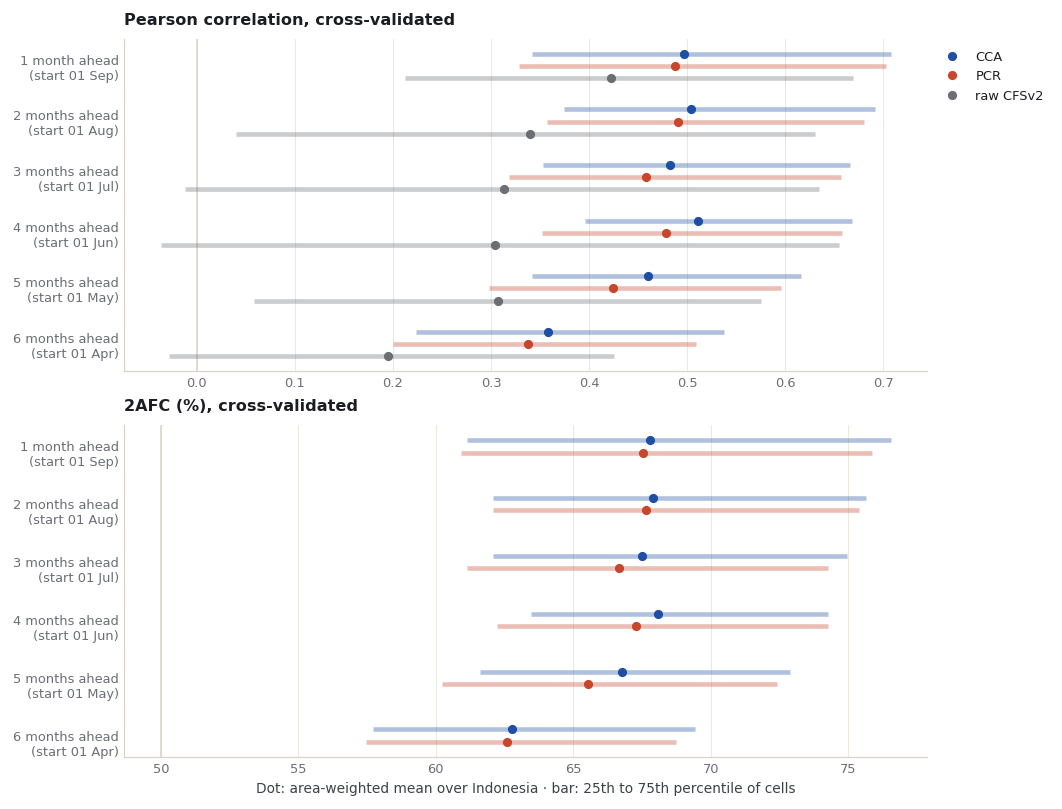

In [12]:
def quartiles(field):
    field = field.where(field > -999).reindex(Y=Y["Y"], X=Y["X"], method="nearest", tolerance=1e-3).where(cells)
    return np.nanpercentile(field.values, [25, 75])


series = {"CCA": figures.ACCENT, "PCR": figures.MARK, "raw CFSv2": figures.MUTED}
panels = [("Pearson", "pearson", "Pearson correlation, cross-validated", 0),
          ("2AFC (%)", "two_alternative_forced_choice", "2AFC (%), cross-validated", 50)]
fig, axes = plt.subplots(len(panels), 1, figsize=(figures.MAP_WIDTH, 7.2), layout="constrained")
for ax, (column, metric, title, reference) in zip(axes, panels):
    ax.axvline(reference, color=figures.LINE, linewidth=1)
    for k, (method, colour) in enumerate(series.items()):
        if method == "raw CFSv2" and metric != "pearson":
            continue
        offset = (k - 1) * 0.22
        for lead in leads:
            field = raw_pearson[lead] if method == "raw CFSv2" else results[lead, method]["skill"][metric]
            low, high = quartiles(field)
            ax.plot([low, high], [lead + offset] * 2, color=colour, linewidth=3, alpha=.35, solid_capstyle="butt")
            ax.plot(skill_by_lead.loc[(lead, method), column], lead + offset, "o", color=colour, markersize=5,
                    label=method if lead == 1 else None)
    ax.set_yticks(leads, [f"{lead} month{'s' if lead > 1 else ''} ahead\n(start {starts[lead]:%d %b})" for lead in leads])
    ax.invert_yaxis()
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
axes[0].legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
axes[-1].set_xlabel("Dot: area-weighted mean over Indonesia · bar: 25th to 75th percentile of cells")
assets = repo / "docs/assets/ond-leads-2023"
assets.mkdir(parents=True, exist_ok=True)
fig.savefig(assets / "skill-by-lead.png")
plt.show()

Where the skill sits matters as much as how much there is. The maps show the
cross-validated CCA correlation at each lead, in one column from one month ahead
(top) to six months ahead (bottom).

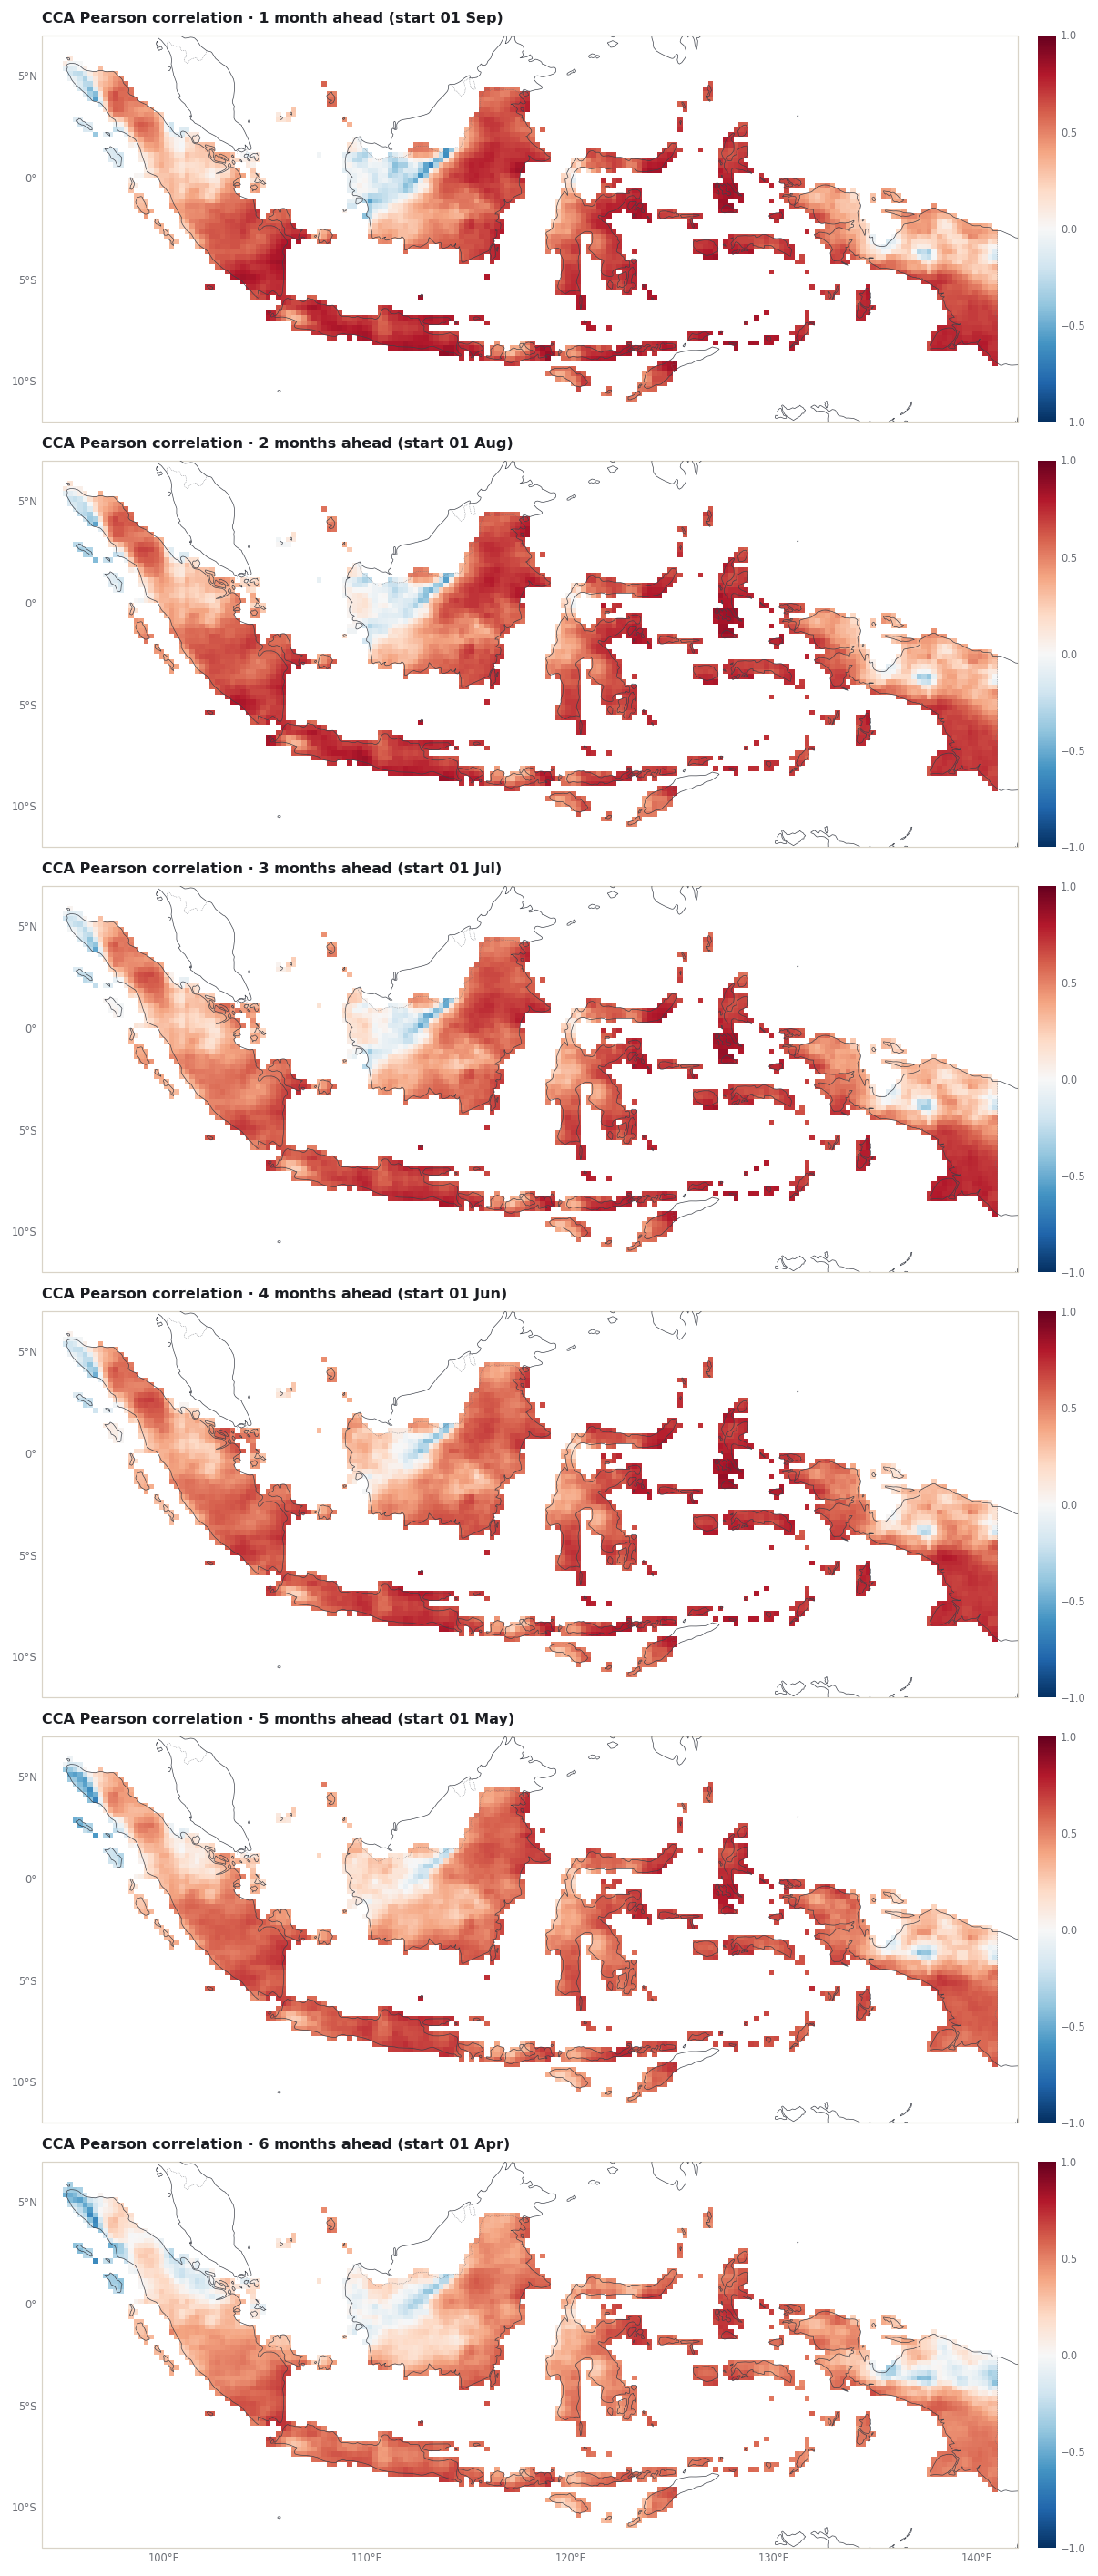

In [13]:
predictand_box = figures.extent_of(predictand_extent)
fig, grid = figures.stacked([figures.map_height(predictand_box)] * len(leads))
for row, lead in enumerate(leads):
    ax = figures.map_axes(fig, grid[row, 0], predictand_box, bottom_labels=row == len(leads) - 1)
    field = results[lead, "CCA"]["skill"].pearson
    image = figures.draw_field(ax, field.where(field > -999), cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_title(f"CCA Pearson correlation · {lead} month{'s' if lead > 1 else ''} ahead (start {starts[lead]:%d %b})")
    figures.colorbar(fig, image, ax, "", ticks=[-1, -.5, 0, .5, 1])
fig.savefig(assets / "cca-pearson-by-lead.png")
plt.show()

## 6. Seasonal and monthly skill by lead

The [monthly case](monthly-leads-2023.ipynb) used the same model, observations,
grid, settings and lead definition for November alone, so the two can be set side
by side. Its scores are read from the file that notebook saved. Lead is counted to
the first month of each target, so at the same lead the seasonal forecast also
covers two later months.

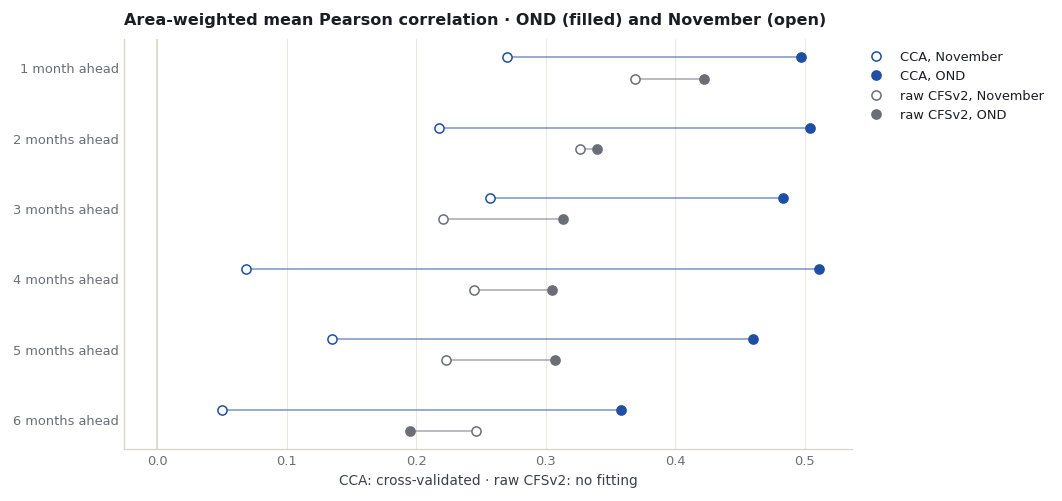

Pearson, OND  Pearson, November  OND minus November
lead method                                                        
1    CCA               0.497              0.270               0.227
     PCR               0.487              0.246               0.242
     raw CFSv2         0.422              0.368               0.054
2    CCA               0.504              0.217               0.287
     PCR               0.491              0.204               0.286
     raw CFSv2         0.340              0.326               0.014
3    CCA               0.483              0.257               0.226
     PCR               0.458              0.228               0.231
     raw CFSv2         0.313              0.221               0.092
4    CCA               0.511              0.068               0.442
     PCR               0.478              0.055               0.423
     raw CFSv2         0.305              0.245               0.060
5    CCA               0.460              0.135               0.325
     PCR               0.424              0.121               0.303
     raw CFSv2         0.307              0.223               0.084
6    CCA               0.358              0.050               0.308
     PCR               0.338              0.043               0.295
     raw CFSv2         0.195              0.246              -0.051

In [14]:
monthly = pd.read_csv(repo / "docs/data/monthly-2023/skill-by-lead.csv").set_index(["lead", "method"])
rows = []
for lead in leads:
    for method in ["CCA", "PCR", "raw CFSv2"]:
        rows.append({"lead": lead, "method": method,
                     "Pearson, OND": skill_by_lead.loc[(lead, method), "Pearson"],
                     "Pearson, November": monthly.loc[(lead, method), "Pearson"]})
comparison = pd.DataFrame(rows).set_index(["lead", "method"])
comparison["OND minus November"] = comparison["Pearson, OND"] - comparison["Pearson, November"]

fig, ax = plt.subplots(figsize=(figures.MAP_WIDTH, 4.4), layout="constrained")
ax.axvline(0, color=figures.LINE, linewidth=1)
for k, (method, colour) in enumerate([("CCA", figures.ACCENT), ("raw CFSv2", figures.MUTED)]):
    offset = (k - .5) * 0.3
    for lead in leads:
        a, b = comparison.loc[(lead, method), ["Pearson, November", "Pearson, OND"]]
        ax.plot([a, b], [lead + offset] * 2, color=colour, linewidth=1.2, alpha=.5)
        ax.plot(a, lead + offset, "o", markerfacecolor="white", markeredgecolor=colour, markersize=6,
                label=f"{method}, November" if lead == 1 else None)
        ax.plot(b, lead + offset, "o", color=colour, markersize=6, label=f"{method}, OND" if lead == 1 else None)
ax.set_yticks(leads, [f"{lead} month{'s' if lead > 1 else ''} ahead" for lead in leads])
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_title("Area-weighted mean Pearson correlation · OND (filled) and November (open)")
ax.set_xlabel("CCA: cross-validated · raw CFSv2: no fitting")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
fig.savefig(assets / "seasonal-vs-monthly.png")
plt.show()
comparison.round(3)

## 7. What happened in October-December 2023

The categories are defined as in [chapter 5](../learn/05-probabilistic-forecasts.ipynb):
at each cell, below normal is under the 33rd percentile of the 1991-2020
OND seasons and above normal over the 67th (NumPy's `hazen` rule, which reproduces
CPT's own probabilities, as chapter 5 shows).

Share of Indonesian area by observed category (%): {'below normal': 76.7, 'near normal': 18.2, 'above normal': 5.1}
Area-weighted mean OND 2023 rainfall: 602 mm, against a 1991-2020 mean of 775 mm


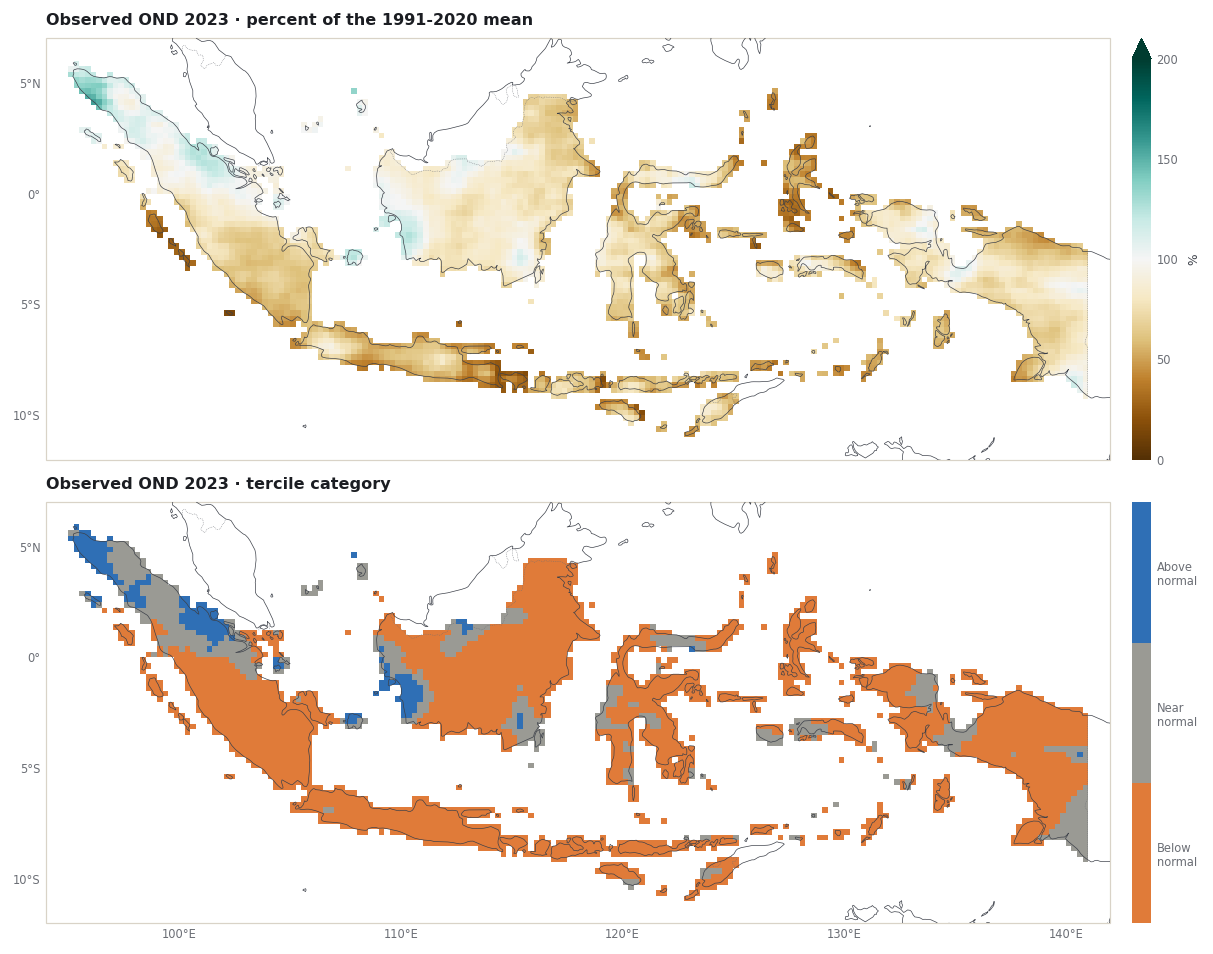

In [15]:
def category_bar(fig, image, ax):
    # a colour bar with the three category names, so every map in a column has the same width
    bar = figures.colorbar(fig, image, ax, "", ticks=[0, 1, 2])
    bar.ax.set_yticklabels(["Below\nnormal", "Near\nnormal", "Above\nnormal"])
    return bar


quantiles = np.quantile(Y.transpose("T", "Y", "X").values, [0.33, 0.67], axis=0, method="hazen")
lower = xr.DataArray(quantiles[0], coords={"Y": Y["Y"], "X": Y["X"]}, dims=("Y", "X")).where(cells)
upper = lower.copy(data=quantiles[1]).where(cells)
observed_category = xr.where(observed_2023 < lower, 0, xr.where(observed_2023 > upper, 2, 1)).where(cells & observed_2023.notnull())
percent_of_mean = (100 * observed_2023 / Y.mean("T")).where(cells)

area = weights.where(observed_category.notnull(), 0)
shares = {name: float(area.where(observed_category == k, 0).sum() / area.sum() * 100)
          for k, name in enumerate(["below normal", "near normal", "above normal"])}
print("Share of Indonesian area by observed category (%):", {k: round(v, 1) for k, v in shares.items()})
print(f"Area-weighted mean OND 2023 rainfall: {float(observed_2023.weighted(weights).mean()):.0f} mm, "
      f"against a 1991-2020 mean of {obs_mean:.0f} mm")

fig, grid = figures.stacked([figures.map_height(predictand_box)] * 2)
ax = figures.map_axes(fig, grid[0, 0], predictand_box, bottom_labels=False)
image = figures.draw_field(ax, percent_of_mean, cmap="BrBG", vmin=0, vmax=200)
ax.set_title("Observed OND 2023 · percent of the 1991-2020 mean")
figures.colorbar(fig, image, ax, "%", extend="max", ticks=[0, 50, 100, 150, 200])
ax = figures.map_axes(fig, grid[1, 0], predictand_box)
category_bar(fig, figures.category_map(ax, observed_category), ax)
ax.set_title("Observed OND 2023 · tercile category")
fig.savefig(assets / "observed-2023.png")
plt.show()

Now the forecasts for that season. Each start gives a probability for each
category at each cell. Three ways to score them against what happened, each
area-weighted over the cells:

- **Hit rate**: share of area where the most likely category was the one observed.
  Always forecasting the same category would hit the area where that category
  happened (the shares above).
- **RPSS 2023**: ranked probability skill score of this one season's probabilities
  against climatological odds (33/34/33%). Above 0 means closer to what
  happened than climatology; it is one season, not a skill estimate.
- **RMSE 2023**: error of the deterministic forecast in mm.

The table also gives the share of the area where each category was the most likely
one, to see whether a hit rate comes from placing categories well or from
favouring the category that happened almost everywhere.

In [16]:
def rps(probability, category):
    cumulative = probability.cumsum("C") / 100
    outcome = xr.concat([(category <= k).astype(float) for k in range(3)], dim="C").assign_coords(C=probability["C"])
    return ((cumulative - outcome) ** 2).isel(C=slice(0, 2)).sum("C")


clim = xr.DataArray([33.0, 34.0, 33.0], dims="C")
valid = observed_category.notnull()
forecast_rows = []
most_likely = {}
for (lead, MOS), r in results.items():
    f = r["fcsts"]
    p = f.probabilistic.isel(T=0).where(lambda a: a > -999).reindex(Y=Y["Y"], X=Y["X"], method="nearest", tolerance=1e-3)
    clim_p = clim.assign_coords(C=p["C"]).broadcast_like(p)
    m = p.fillna(-1).argmax("C").where(p.notnull().all("C") & valid)
    most_likely[lead, MOS] = (m, p.max("C"))
    w = weights.where(m.notnull(), 0)                       # cells with both a forecast and an observation
    det = f.deterministic.isel(T=0).where(lambda a: a > -999).reindex(Y=Y["Y"], X=Y["X"], method="nearest", tolerance=1e-3)
    forecast_rows.append({"lead": lead, "method": MOS,
                          "hit rate (%)": float(w.where(m == observed_category, 0).sum() / w.sum() * 100),
                          "RPSS 2023": float(1 - rps(p, observed_category).weighted(w).mean() / rps(clim_p, observed_category).weighted(w).mean()),
                          "RMSE 2023 (mm)": float(np.sqrt(((det - observed_2023) ** 2).weighted(w).mean())),
                          "mean forecast (mm)": float(det.weighted(w).mean()),
                          **{f"area forecast {name} (%)": float(w.where(m == k, 0).sum() / w.sum() * 100)
                             for k, name in enumerate(["below", "near", "above"])}})
forecast_2023 = pd.DataFrame(forecast_rows).set_index(["lead", "method"]).sort_index()
print(f"Reference: forecasting below normal everywhere would hit {shares['below normal']:.1f}% of the area")
forecast_2023.round(2)

Reference: forecasting below normal everywhere would hit 76.7% of the area


hit rate (%)  RPSS 2023  RMSE 2023 (mm)  mean forecast (mm)  \
lead method                                                                
1    CCA            77.64       0.59          124.08              601.99   
     PCR            77.17       0.58          118.68              601.78   
2    CCA            77.55       0.59          125.33              598.81   
     PCR            77.30       0.59          121.50              596.46   
3    CCA            78.04       0.51          138.65              652.95   
     PCR            77.18       0.50          137.11              651.85   
4    CCA            77.55       0.60          125.25              583.26   
     PCR            77.36       0.59          126.19              581.83   
5    CCA            77.79       0.57          126.47              620.91   
     PCR            77.05       0.56          129.25              619.70   
6    CCA            69.68       0.31          179.22              714.27   
     PCR            69.25       0.30          183.26              716.26   

             area forecast below (%)  area forecast near (%)  \
lead method                                                    
1    CCA                       95.98                    0.62   
     PCR                       95.67                    0.56   
2    CCA                       97.12                    0.34   
     PCR                       96.85                    0.25   
3    CCA                       95.52                    1.33   
     PCR                       94.90                    1.33   
4    CCA                       97.49                    0.49   
     PCR                       97.31                    0.31   
5    CCA                       96.47                    0.87   
     PCR                       95.73                    0.56   
6    CCA                       73.09                   20.14   
     PCR                       73.64                   16.54   

             area forecast above (%)  
lead method                           
1    CCA                        3.40  
     PCR                        3.77  
2    CCA                        2.54  
     PCR                        2.91  
3    CCA                        3.15  
     PCR                        3.77  
4    CCA                        2.01  
     PCR                        2.38  
5    CCA                        2.66  
     PCR                        3.71  
6    CCA                        6.77  
     PCR                        9.83

The CCA forecasts' most likely category at each lead, in one column with the
observed category on top for comparison. The colour shows the category; maps of
the probabilities themselves are in chapter 5.

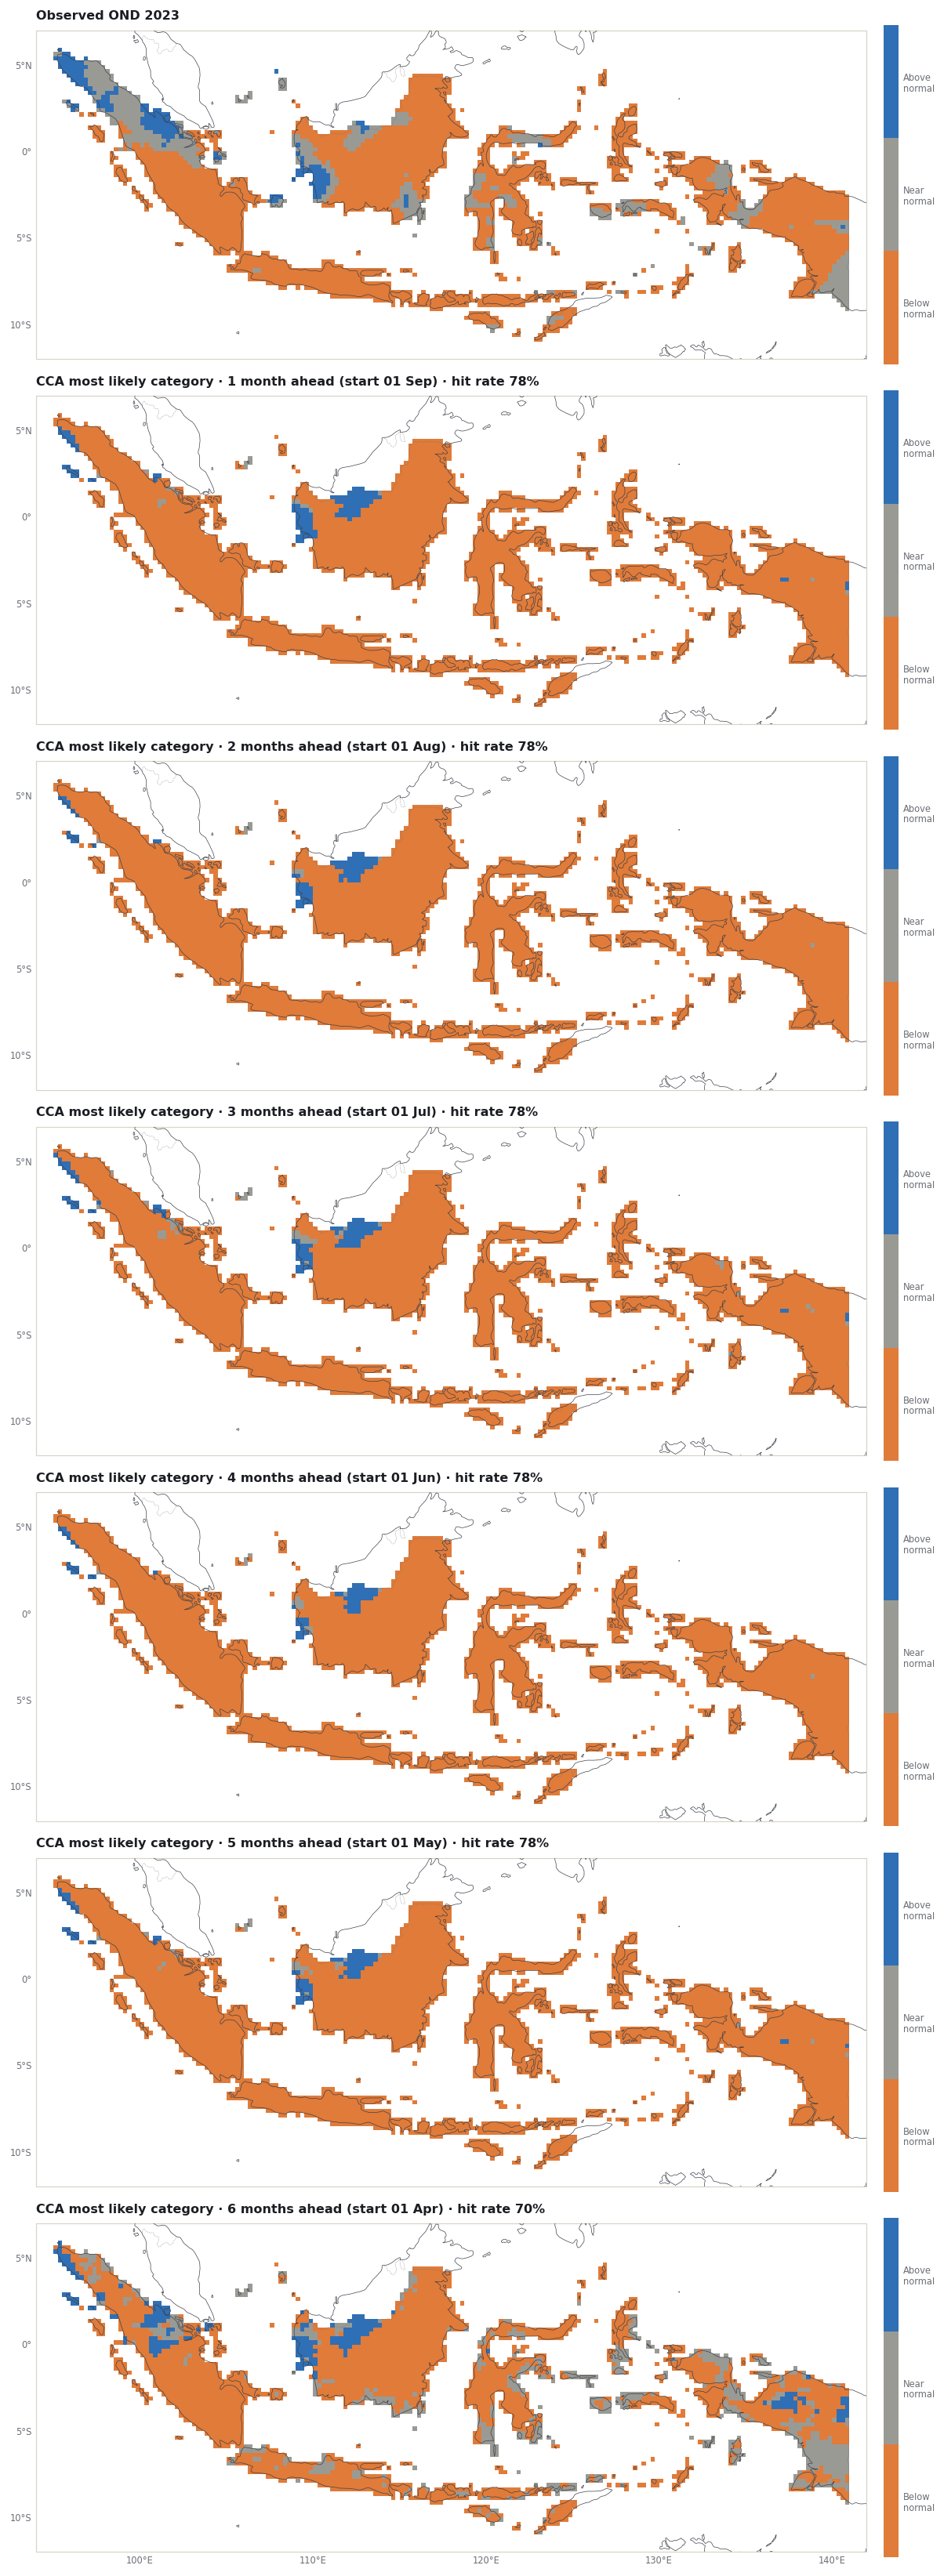

In [17]:
fig, grid = figures.stacked([figures.map_height(predictand_box)] * (len(leads) + 1))
ax = figures.map_axes(fig, grid[0, 0], predictand_box, bottom_labels=False)
category_bar(fig, figures.category_map(ax, observed_category), ax)
ax.set_title("Observed OND 2023")
for row, lead in enumerate(leads, start=1):
    ax = figures.map_axes(fig, grid[row, 0], predictand_box, bottom_labels=row == len(leads))
    category_bar(fig, figures.category_map(ax, most_likely[lead, "CCA"][0]), ax)
    hit = forecast_2023.loc[(lead, "CCA"), "hit rate (%)"]
    ax.set_title(f"CCA most likely category · {lead} month{'s' if lead > 1 else ''} ahead (start {starts[lead]:%d %b}) · hit rate {hit:.0f}%")
fig.savefig(assets / "cca-category-by-lead.png")
plt.show()

## 8. Save the results

The story page quotes these tables and shows these figures.

In [18]:
data_dir = repo / "docs/data/ond-leads-2023"
data_dir.mkdir(parents=True, exist_ok=True)
skill_by_lead.round(4).to_csv(data_dir / "skill-by-lead.csv")
forecast_2023.round(4).to_csv(data_dir / "ond-2023-forecasts.csv")
comparison.round(4).to_csv(data_dir / "seasonal-vs-monthly.csv")
summary = {"target": "October-December 2023", "leads_months": leads,
           "starts": {lead: s.date().isoformat() for lead, s in starts.items()},
           "training_years": [training_years[0], training_years[-1]], "cells": int(cells.sum()),
           "settings": {k: str(v) for k, v in cpt_args.items()},
           "observed_category_area_percent": {k: round(v, 2) for k, v in shares.items()},
           "observed_mean_2023_mm": round(float(observed_2023.weighted(weights).mean()), 2),
           "observed_mean_1991_2020_mm": round(obs_mean, 2),
           "fit_seconds": {f"{lead}-{m}": round(r["seconds"], 1) for (lead, m), r in results.items()}}
(data_dir / "summary.json").write_text(json.dumps(summary, indent=2) + "\n")
maps = xr.Dataset({"observed_2023": observed_2023.reset_coords(drop=True),
                   "observed_category_2023": observed_category.reset_coords(drop=True)})
for (lead, MOS), r in results.items():
    maps[f"{MOS.lower()}_pearson_lead{lead}"] = r["skill"].pearson.where(lambda a: a > -999).reindex(
        Y=Y["Y"], X=Y["X"], method="nearest", tolerance=1e-3).reset_coords(drop=True)
    maps[f"{MOS.lower()}_most_likely_lead{lead}"] = most_likely[lead, MOS][0].reset_coords(drop=True)
save_netcdf(maps, data_dir / "ond-leads-2023-maps.nc", overwrite=True,
            metadata={"note": "OND 2023 CFSv2 forecasts at leads 1-6 months, CCA and PCR; categories 0 below, 1 near, 2 above normal"})
for f in sorted(data_dir.iterdir()) + sorted(assets.iterdir()):
    print(f"{f.relative_to(repo)}  ({f.stat().st_size / 1000:.0f} kB)")

docs/data/ond-leads-2023/ond-2023-forecasts.csv  (1 kB)
docs/data/ond-leads-2023/ond-leads-2023-maps.nc  (524 kB)
docs/data/ond-leads-2023/seasonal-vs-monthly.csv  (1 kB)
docs/data/ond-leads-2023/skill-by-lead.csv  (1 kB)
docs/data/ond-leads-2023/summary.json  (1 kB)
docs/assets/ond-leads-2023/cca-category-by-lead.png  (1301 kB)
docs/assets/ond-leads-2023/cca-pearson-by-lead.png  (1164 kB)
docs/assets/ond-leads-2023/observed-2023.png  (384 kB)
docs/assets/ond-leads-2023/seasonal-vs-monthly.png  (74 kB)
docs/assets/ond-leads-2023/skill-by-lead.png  (131 kB)


## References {.unnumbered .reference-section}

1. IRI. *PyCPT 2.10.4 source: `pycpt/src/pycpt/notebook.py`* (`setup`, `download_data`, `summarize_available_years`, `evaluate_models` and the plotting functions). Tag pycpt-2.10.4, commit 084bb5c. <https://github.com/iri-pycpt/pycpt/blob/084bb5c380c200b5f65f11ba224a965547b91da1/pycpt/src/pycpt/notebook.py>
2. IRI. *PyCPT 2.10.4 source: `cptdl`* (data catalog, `leads_from_target`, `evaluate_url`, `download`, `simple_download`). Tag pycpt-2.10.4, commit 084bb5c. <https://github.com/iri-pycpt/pycpt/tree/084bb5c380c200b5f65f11ba224a965547b91da1/pycpt/src/cptdl>
3. IRI. *CPT 17.8.3 source code archive*. Columbia University Academic Commons. <https://doi.org/10.7916/fdp6-v391>
4. CPT+. *Forecast Probabilities* (CPT help). <https://cptplus.org/Help/Tools_Forecast_Probs.html> Same page name as on the former cpthelp.iri.columbia.edu, which did not resolve when checked on 10 November 2026.
5. IRI Data Library. *NMME NCEP-CFSv2 hindcasts, PENTAD_SAMPLES_FULL, precipitation*. <https://iridl.ldeo.columbia.edu/SOURCES/.Models/.NMME/.NCEP-CFSv2/.HINDCAST/.PENTAD_SAMPLES_FULL/.prec/> Browsing Data Library pages requires signing in (checked 10 November 2026); PyCPT's data requests in this tutorial succeeded without a key.
6. Saha, S., Moorthi, S., Wu, X., et al. (2014). The NCEP Climate Forecast System Version 2. *Journal of Climate*, 27(6), 2185-2208. <https://doi.org/10.1175/JCLI-D-12-00823.1>
7. Climate Hazards Center, UC Santa Barbara. *CHIRPS: Rainfall Estimates from Rain Gauge and Satellite Observations* (CHIRPS version 3.0 page). <https://www.chc.ucsb.edu/data/chirps3>
8. Funk, C., Peterson, P., Landsfeld, M., et al. (2014). *A quasi-global precipitation time series for drought monitoring*. U.S. Geological Survey Data Series 832. <https://doi.org/10.3133/ds832>
9. Natural Earth. *Admin 0: Countries*, 1:10m cultural vectors. <https://www.naturalearthdata.com/downloads/10m-cultural-vectors/10m-admin-0-countries/>
10. Shapely. *shapely.contains_xy*. <https://shapely.readthedocs.io/en/stable/reference/shapely.contains_xy.html>
11. NumPy. *numpy.quantile* (NumPy manual). <https://numpy.org/doc/stable/reference/generated/numpy.quantile.html>
12. Mason, S. J., and Weigel, A. P. (2009). A generic forecast verification framework for administrative purposes. *Monthly Weather Review*, 137(1), 331-349. <https://doi.org/10.1175/2008MWR2553.1>
13. Epstein, E. S. (1969). A scoring system for probability forecasts of ranked categories. *Journal of Applied Meteorology*, 8(6), 985-987. <https://doi.org/10.1175/1520-0450(1969)008%3C0985:ASSFPF%3E2.0.CO;2>
14. Barnston, A. G., and van den Dool, H. M. (1993). A degeneracy in cross-validated skill in regression-based forecasts. *Journal of Climate*, 6(5), 963-977. <https://doi.org/10.1175/1520-0442(1993)006%3C0963:ADICVS%3E2.0.CO;2>
15. SciTools. *Cartopy* (documentation). <https://scitools.org.uk/cartopy/docs/latest/>